# Week 9 — Tumour types from gene expression (TCGA)

**27200 Data-driven Bioengineering**

We use a public extract of **The Cancer Genome Atlas (TCGA)**: RNA-seq gene expression of **801 tumours**
from five cancer types, each measured on **20,531 genes**:

| Code | Tumour type |
|---|---|
| BRCA | breast invasive carcinoma |
| KIRC | kidney renal clear cell carcinoma |
| COAD | colon adenocarcinoma |
| LUAD | lung adenocarcinoma |
| PRAD | prostate adenocarcinoma |

Run the cells in order, top to bottom. Questions are marked **Question x.y**; answer them in the text cells or discuss them
in your group. Change the parameters marked in the code cells and rerun them to see what happens.

In [205]:
!pip install -q umap-learn seaborn

# --- libraries ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import io, tarfile, urllib.request, zipfile            # for downloading the data

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import balanced_accuracy_score, ConfusionMatrixDisplay

# --- plot style and settings used throughout the notebook ---
sns.set_style("ticks")
plt.rcParams["figure.dpi"] = 600
SEED = 27200                                           # fixed random seed so results are reproducible
PALETTE = ["#b7094c", "#a01a58", "#892b64", "#723c70", "#5c4d7d", "#455e89", "#2e6f95", "#1780a1", "#0091ad"]
COLOURS = {"BRCA": PALETTE[0], "KIRC": PALETTE[2], "COAD": PALETTE[4], "LUAD": PALETTE[6], "PRAD": PALETTE[8]}   # one colour per tumour type, evenly spaced along the palette
PC_COLOURS = {"PC1": PALETTE[1], "PC2": PALETTE[3], "PC3": PALETTE[5], "PC4": PALETTE[7]}   # one colour per component

# Load the data

The dataset is hosted by the UCI Machine Learning Repository (Fiorini, 2016,
https://doi.org/10.24432/C5R88H, CC BY 4.0). The download (about 70 MB) takes a minute.

UCI only labels the genes `gene_0 … gene_20530`. The file `tcga_gene_names.txt` (next to this notebook) holds the
matching gene symbols, recovered from the TCGA RSEM gene order (alphabetical by symbol). Genes without an
official symbol are called `unknown_<Entrez id>`.

After this part we have two objects: `expr` (samples × genes table of expression values) and `tumour`
(the tumour type of each sample).

In [206]:
# Download the zip from UCI and unpack it in memory (nothing is saved to disk)
URL = "https://archive.ics.uci.edu/static/public/401/gene+expression+cancer+rna+seq.zip"
with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read())) as z:
    tar_bytes = z.read(z.namelist()[0])                # the zip contains a .tar.gz archive
with tarfile.open(fileobj=io.BytesIO(tar_bytes), mode="r:gz") as tar:
    raw = pd.read_csv(tar.extractfile("TCGA-PANCAN-HiSeq-801x20531/data.csv"), index_col=0)       # expression values
    labels = pd.read_csv(tar.extractfile("TCGA-PANCAN-HiSeq-801x20531/labels.csv"), index_col=0)  # tumour type per sample

# Expression table: rows = samples, columns = genes
expr = raw[[c for c in raw.columns if c.startswith("gene_")]].astype(np.float32)   # keep the gene columns, smaller dtype saves memory
gene_names = pd.read_csv("tcga_gene_names.txt", header=None)[0].tolist()           # gene symbols, same order as the columns
assert len(gene_names) == expr.shape[1]                                            # sanity check: one name per gene
expr.columns = gene_names                                                          # replace gene_0 ... with real gene symbols

# Tumour type of each sample (BRCA, KIRC, COAD, LUAD, PRAD)
tumour = labels["Class"].rename("tumour_type")
print("expression table:", expr.shape, "(samples x genes)")

expression table: (801, 20531) (samples x genes)


# 1 - Inspect the data

First look at the size of the table, how many values are zero, and how many samples each tumour type has.

In [207]:
print(f"{expr.shape[0]} samples, {expr.shape[1]} genes")
print(f"fraction of zero values: {(expr.to_numpy() == 0).mean():.1%}")
print(f"genes that are zero in every sample: {(expr.max(axis=0) == 0).sum()}")
print()
print(tumour.value_counts().to_string())      # number of samples per tumour type
expr.iloc[:5, :8]                             # first 5 samples, first 8 genes

801 samples, 20531 genes
fraction of zero values: 14.2%
genes that are zero in every sample: 267

tumour_type
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78


,unknown_100130426,unknown_100133144,unknown_100134869,unknown_10357,unknown_10431,unknown_136542,unknown_155060,unknown_26823
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595
sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882
sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982


**Question 1.1** How many samples and genes are there? How many samples per tumour type: is the dataset
balanced? What could explain genes that are zero in every sample?

*Your answer:*

# 2 - Distributions of the values

Histograms of four example genes, from very highly to lowly expressed, coloured by tumour type.

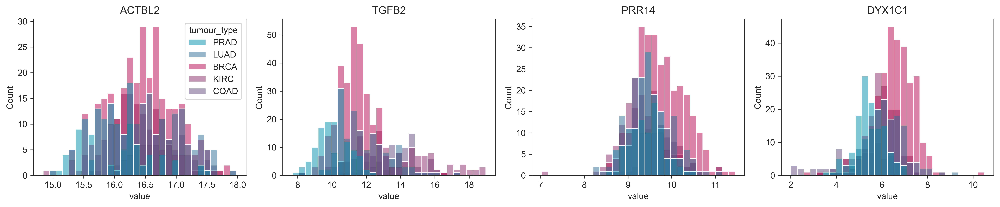

value range: 0.00 to 20.78


In [208]:
# Pick 4 example genes spread from very high to low mean expression
order_by_mean = expr.mean(axis=0).sort_values(ascending=False).index
example_genes = [order_by_mean[int(q * (len(order_by_mean) - 1))] for q in (0, 0.03, 0.25, 0.6)]   # quantiles of the ranking

# One histogram per gene, coloured by tumour type
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4))
for a, g in zip(ax, example_genes):
    sns.histplot(x=expr[g], hue=tumour, palette=COLOURS, bins=30, alpha=0.5, ax=a, legend=(a is ax[0]))   # legend only on the first panel
    a.set(title=g, xlabel="value")
plt.tight_layout(); plt.show()
print(f"value range: {expr.to_numpy().min():.2f} to {expr.to_numpy().max():.2f}")

**Question 2.1** Are the features representative of raw NGS data? What distribution does NGS data follow? What transformation could have been applied here?

*Your answers:*

**Question 2.2** What type of data does LC/MS-based proteomics provide (Binomial, Poisson, Gaussian)? Would a log-transformation affect it differently than NGS data?

*Your answers:*

# 3 - Principal component analysis (PCA)

PCA finds the directions (principal components, PCs) along which the samples vary most. Each sample gets a
score on every PC, and each gene a **loading** (weight) telling how much it contributes to that PC.
Here we run PCA on the values as they are, without any cleaning, to see what dominates the variation.

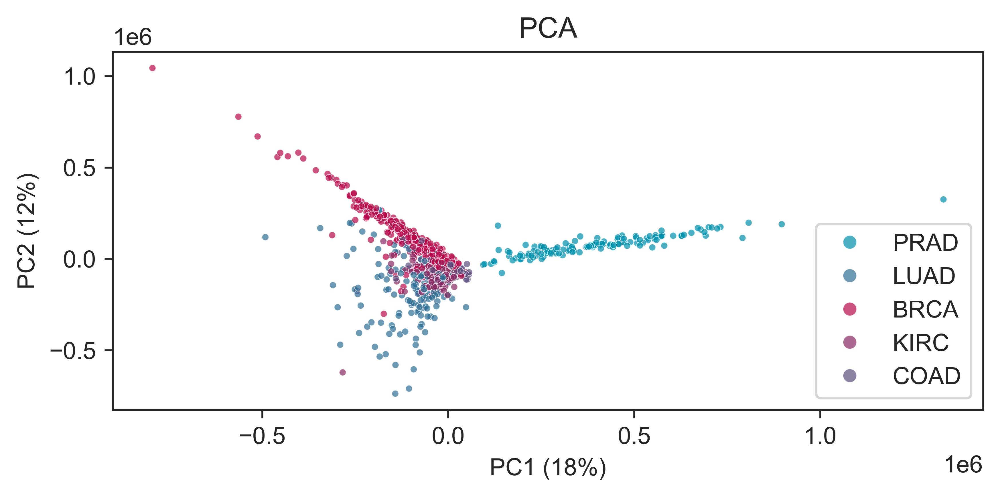

In [209]:
# The values look log-transformed, so undo it (2^x - 1) to see what PCA does on the linear scale
linear = np.exp2(expr.to_numpy()) - 1

# PCA keeping the first 10 components; the data is only centred (mean 0 per gene), not scaled
pca = PCA(n_components=10, random_state=SEED)
scores_lin = pca.fit_transform(linear - linear.mean(axis=0))     # scores = coordinates of each sample on the PCs
e = pca.explained_variance_ratio_                                 # fraction of the variance explained by each PC

# Samples on PC1 vs PC2, coloured by tumour type
fig, ax = plt.subplots(figsize=(6,3))
sns.scatterplot(x=scores_lin[:, 0], y=scores_lin[:, 1], hue=tumour, palette=COLOURS, s=8, alpha=0.7, ax=ax)
ax.set(xlabel=f"PC1 ({e[0]:.0%})", ylabel=f"PC2 ({e[1]:.0%})", title="PCA"); ax.legend(markerscale=2, title=None)
plt.tight_layout(); plt.show()

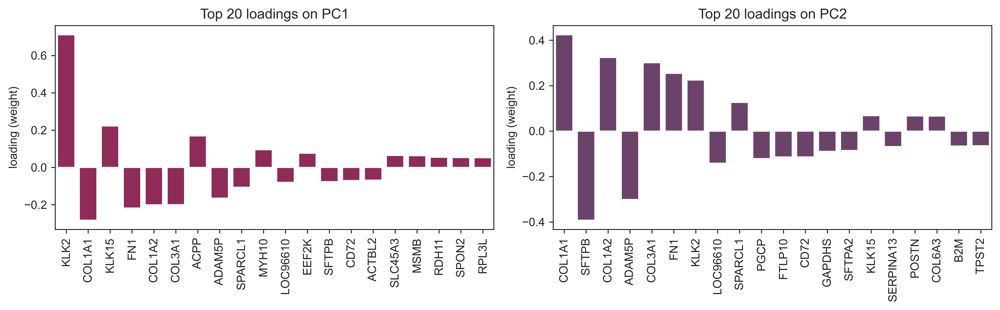

In [210]:
# Loadings = how much each gene contributes to a PC. Here: the genes with the largest |loading| on PC1 and PC2
N_TOP = 20
loads = [pd.Series(pca.components_[pc], index=expr.columns) for pc in (0, 1)]    # one loading per gene, for PC1 and PC2

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, pc, load in zip(ax, (1, 2), loads):
    top = load.abs().nlargest(N_TOP).index                  # genes with the largest absolute loading (sign = direction)
    sns.barplot(x=top, y=load[top], color=PC_COLOURS[f"PC{pc}"], ax=a)
    a.tick_params(axis="x", rotation=90)
    a.set(xlabel="", ylabel="loading (weight)", title=f"Top {N_TOP} loadings on PC{pc}")
plt.tight_layout(); plt.show()

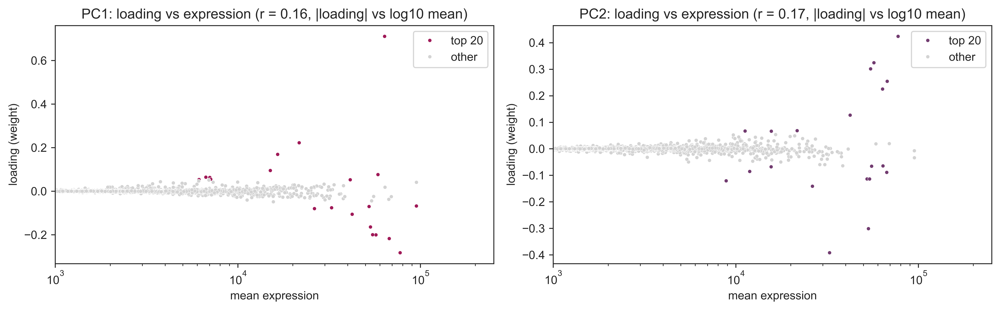

In [211]:
# Is a gene's loading related to how highly it is expressed?
mean_linear = pd.Series(linear.mean(axis=0), index=expr.columns)     # mean expression per gene (linear scale)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, pc, load in zip(ax, (1, 2), loads):
    df = pd.DataFrame({"mean expression": mean_linear, "loading": load})
    df["group"] = "other"
    df.loc[load.abs().nlargest(N_TOP).index, "group"] = f"top {N_TOP}"     # mark the top genes from the previous plot
    r = np.corrcoef(np.log10(mean_linear + 1), load.abs())[0, 1]           # correlation between |loading| and log10 mean expression
    sns.scatterplot(data=df.sort_values("group", ascending=False), x="mean expression", y="loading", hue="group",
                    palette={"other": "lightgrey", f"top {N_TOP}": PC_COLOURS[f"PC{pc}"]}, s=10, ax=a)
    a.set(xscale="log", ylabel="loading (weight)", title=f"PC{pc}: loading vs expression (r = {r:.2f}, |loading| vs log10 mean)")
    a.set_xlim(left=1e3)   # genes below 10^3 are not shown
    a.legend(title=None)
plt.tight_layout(); plt.show()

**Question 3.1** Do the tumour types separate? Which genes have the largest loadings on PC1? Why do the most highly expressed genes dominate the PC loadings?

*Your answers:*

# 4 - Do we need normalization?

Each box is one sample (the first 40), showing its values over all genes that are expressed (value > 0).
If samples had different sequencing depths, their boxes would sit at different heights.

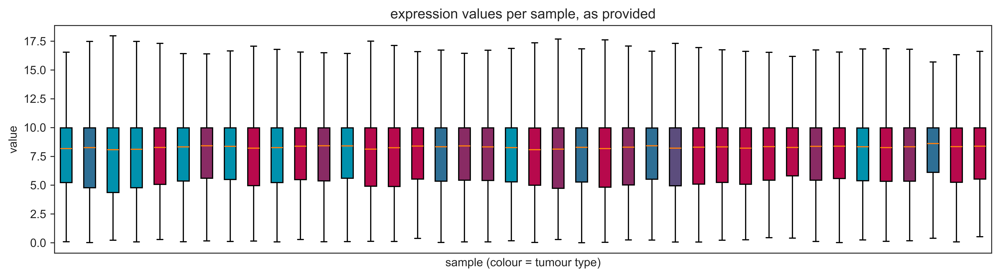

In [212]:
def sample_boxplots(M, title, n=40):
    """Boxplot of the non-zero values of each of the first n samples (rows of M), coloured by tumour type."""
    fig, ax = plt.subplots(figsize=(12, 3.4))
    bp = ax.boxplot([r[r > 0] for r in M[:n]], showfliers=False, patch_artist=True)   # one box per sample
    for patch, t in zip(bp["boxes"], tumour.iloc[:n]):
        patch.set_facecolor(COLOURS[t])
    ax.set(title=title, xlabel="sample (colour = tumour type)", ylabel="value"); ax.set_xticks([])
    plt.tight_layout(); plt.show()

sample_boxplots(expr.to_numpy(), "expression values per sample, as provided")

**Question 4.1** Do the samples look comparable, or do they need further normalization? Has between-sample
normalization been done already? What would you look for if it had not?

*Your answers:*

# 5 - Data preprocessing and PCA interpretation

1. **Filter**: remove genes that are zero in most samples; they carry little information.
2. **Select highly variable genes**: keep the 2,000 genes with the largest variance.
3. **Scale**: mean 0 and variance 1 per gene, so highly expressed genes do not dominate.

Then we repeat the PCA on the cleaned matrix.

Removed 2810 of genes
Keeping 2000 HVG


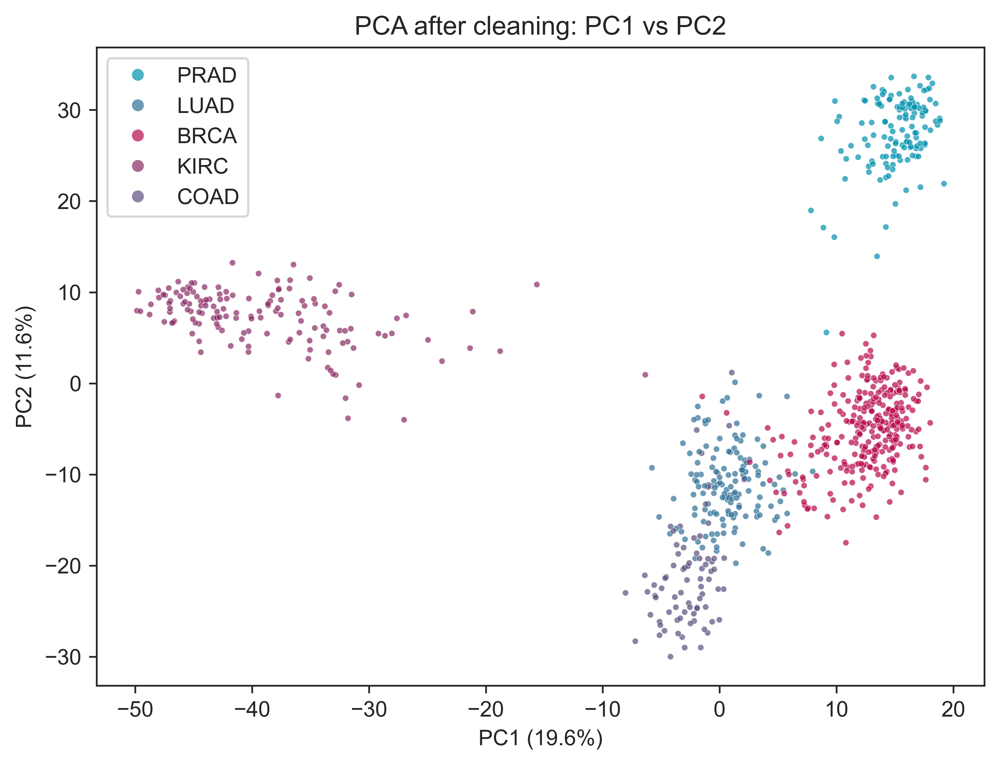

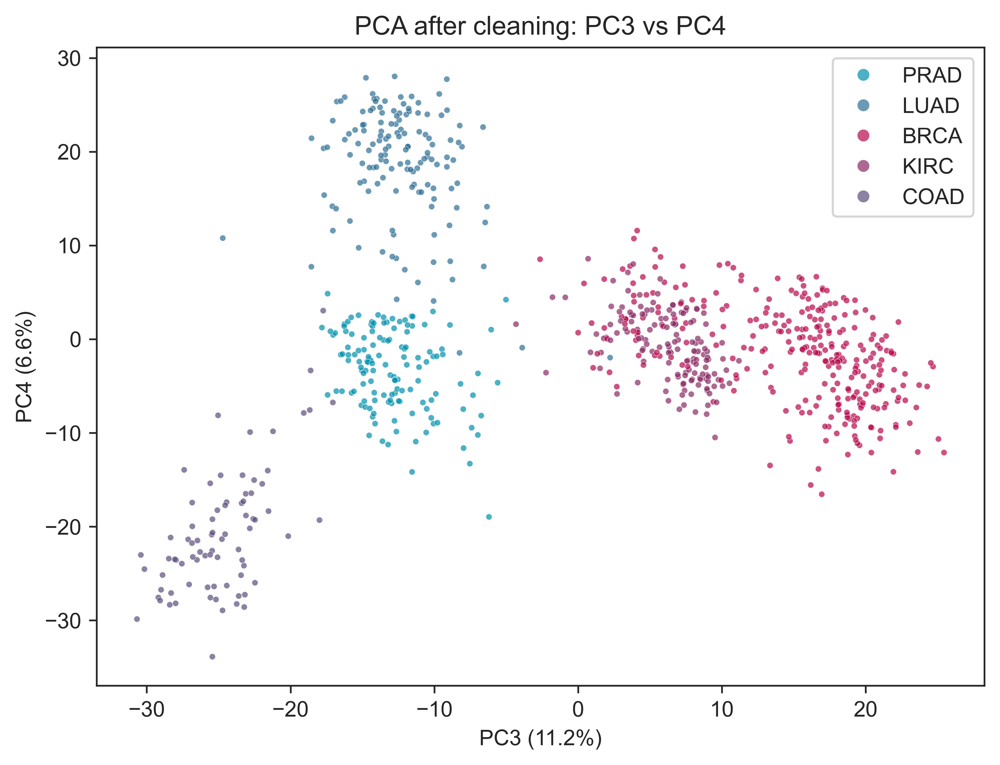

In [213]:
# --- Step 1: filter out genes that are zero in most samples ---
MIN_FRACTION_EXPRESSED = 0.5                      # keep genes expressed (> 0) in at least this fraction of samples; try e.g. 0.1, 0.5, 0.9 (Question 5.2)
expressed = (expr > 0).mean(axis=0) >= MIN_FRACTION_EXPRESSED
filt = expr.loc[:, expressed]
print(f"Removed {expr.shape[1] - filt.shape[1]} of {expr.shape[1]} genes")

# --- Step 2: keep the most variable genes ---
N_HVG = 2000                                      # number of genes to keep; try e.g. 100, 500, 1000, 5000 (Question 5.2)
hvg = filt.var(axis=0).sort_values(ascending=False).index[:N_HVG]
print(f"Keeping the {N_HVG} most variable genes")

# --- Step 3: scale each gene to mean 0 and variance 1, then run PCA ---
X = StandardScaler().fit_transform(filt[hvg])
pca = PCA(n_components=50, random_state=SEED)
scores = pca.fit_transform(X)                     # coordinates of each sample on the 50 PCs
evr = pca.explained_variance_ratio_               # fraction of variance explained by each PC

# --- Plot PC1 vs PC2 and PC3 vs PC4, coloured by tumour type ---
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(x=scores[:, 0], y=scores[:, 1], hue=tumour, palette=COLOURS, s=8, alpha=0.7, ax=ax)
ax.set(xlabel=f"PC1 ({evr[0]:.1%})", ylabel=f"PC2 ({evr[1]:.1%})", title="PCA after cleaning: PC1 vs PC2"); ax.legend(markerscale=2, title=None)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(x=scores[:, 2], y=scores[:, 3], hue=tumour, palette=COLOURS, s=8, alpha=0.7, ax=ax)
ax.set(xlabel=f"PC3 ({evr[2]:.1%})", ylabel=f"PC4 ({evr[3]:.1%})", title="PCA after cleaning: PC3 vs PC4"); ax.legend(markerscale=2, title=None)
plt.tight_layout(); plt.show()

**Question 5.1** How does the new PCA plot differ from the previous? Why do we need multiple PCs to separate the cancer types?

*Your answers:*

**Question 5.2** Change `MIN_FRACTION_EXPRESSED` and `N_HVG` in the cell above and rerun it. How does the separation of the tumour types change, for example with only 50 genes, or with no filtering and all genes? Which setting would you choose, and why?

*Your answers:*

**Question 5.3** Can we make assumptions on the similarity of samples based on their distance in PCA space (how far apart they are in different PC dimensions)? If we had no cancer type labels available, could we still categorize the samples from their RNA-seq data? If so, how would we do it? 

*Your answers:*

## Loading interpretation

How much variance do the components explain, and which genes drive the first four PCs?

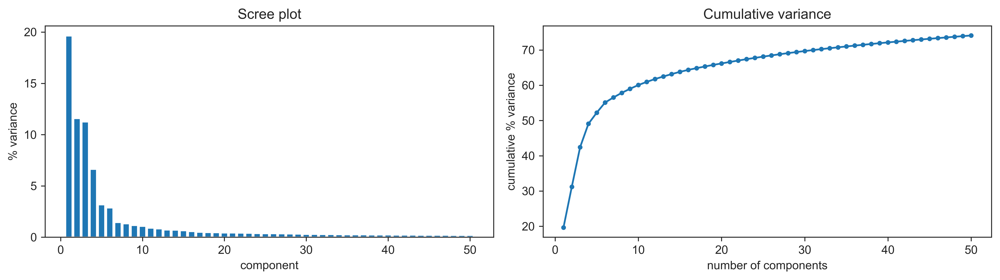

In [214]:
# Scree plot (variance per PC) and cumulative variance explained
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
n = len(evr)
ax[0].bar(range(1, n + 1), evr * 100); ax[0].set(xlabel="component", ylabel="% variance", title="Scree plot")
ax[1].plot(range(1, n + 1), np.cumsum(evr) * 100, marker="o", ms=3)
ax[1].set(xlabel="number of components", ylabel="cumulative % variance", title="Cumulative variance")
plt.tight_layout(); plt.show()

**Question 5.4** Why is the cumulative variance still far below 100 % although we can separate all the cancer types?

*Your answer:*

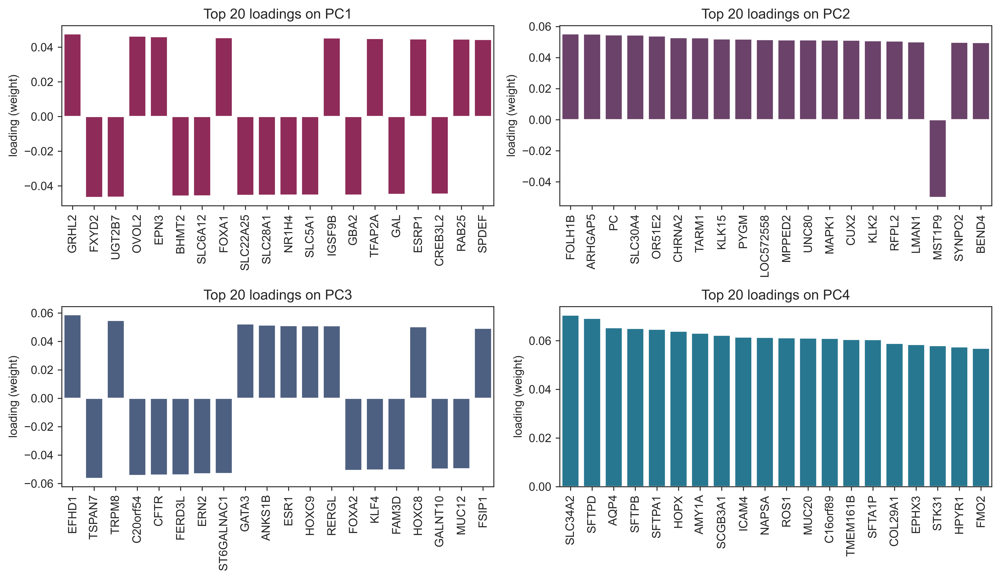

In [215]:
# Top loadings for PC1-PC4 (now on the cleaned, scaled data)
N_TOP = 20
loadings = pd.DataFrame(pca.components_[:4].T, index=hvg, columns=["PC1", "PC2", "PC3", "PC4"])   # rows = genes, columns = PCs

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for a, pc in zip(ax.ravel(), loadings.columns):
    top = loadings[pc].abs().nlargest(N_TOP).index          # genes with the largest absolute loading
    sns.barplot(x=top, y=loadings.loc[top, pc], color=PC_COLOURS[pc], ax=a)
    a.tick_params(axis="x", rotation=90)
    a.set(xlabel="", ylabel="loading (weight)", title=f"Top {N_TOP} loadings on {pc}")
plt.tight_layout(); plt.show()

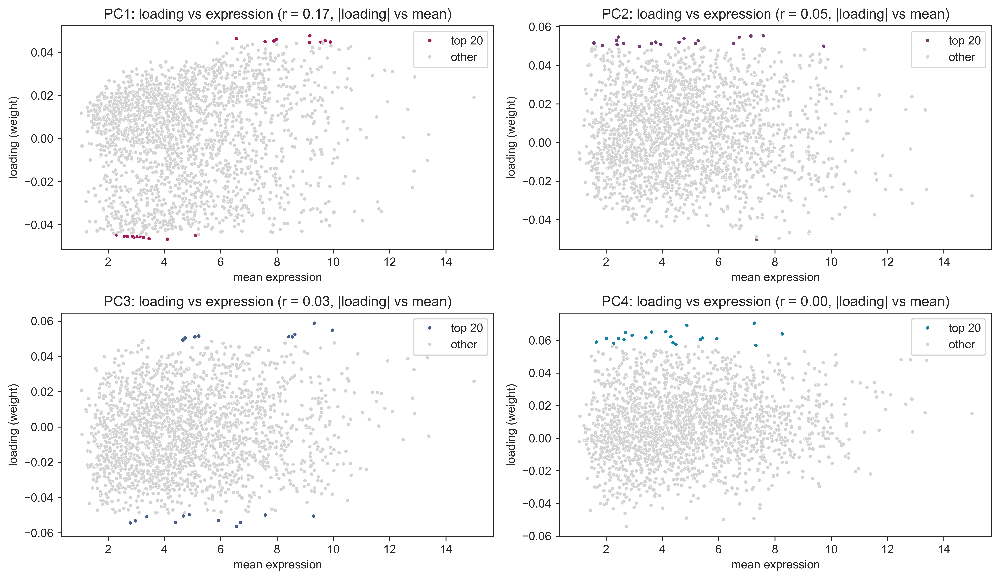

In [216]:
# Loading vs mean expression, as before: after scaling, high expression should no longer give high loadings
mean_expr = filt[hvg].mean(axis=0)                           # mean (log-scale) expression per selected gene

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for a, pc in zip(ax.ravel(), loadings.columns):
    df = pd.DataFrame({"mean expression": mean_expr, "loading": loadings[pc]})
    df["group"] = "other"
    df.loc[df["loading"].abs().nlargest(N_TOP).index, "group"] = f"top {N_TOP}"     # mark the top genes from the previous plot
    r = np.corrcoef(df["mean expression"], df["loading"].abs())[0, 1]              # correlation between |loading| and mean expression
    sns.scatterplot(data=df.sort_values("group", ascending=False), x="mean expression", y="loading", hue="group",
                    palette={"other": "lightgrey", f"top {N_TOP}": PC_COLOURS[pc]}, s=10, ax=a)
    a.set(ylabel="loading (weight)", title=f"{pc}: loading vs expression (r = {r:.2f}, |loading| vs mean)")
    a.legend(title=None)
plt.tight_layout(); plt.show()

**Question 5.5** We observe that the separation-driving genes (highest loadings on the PCs) are no longer intensity dependent. How would we identify whether these genes work together or are part of distinct molecular pathways? 

*Your answer:*

# 6 - UMAP

UMAP is a non-linear method that places samples with similar expression close together in 2D.
We run it on the first PCs from Part 5, not on the raw genes (faster and less noisy).

/opt/homebrew/Caskroom/miniforge/base/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


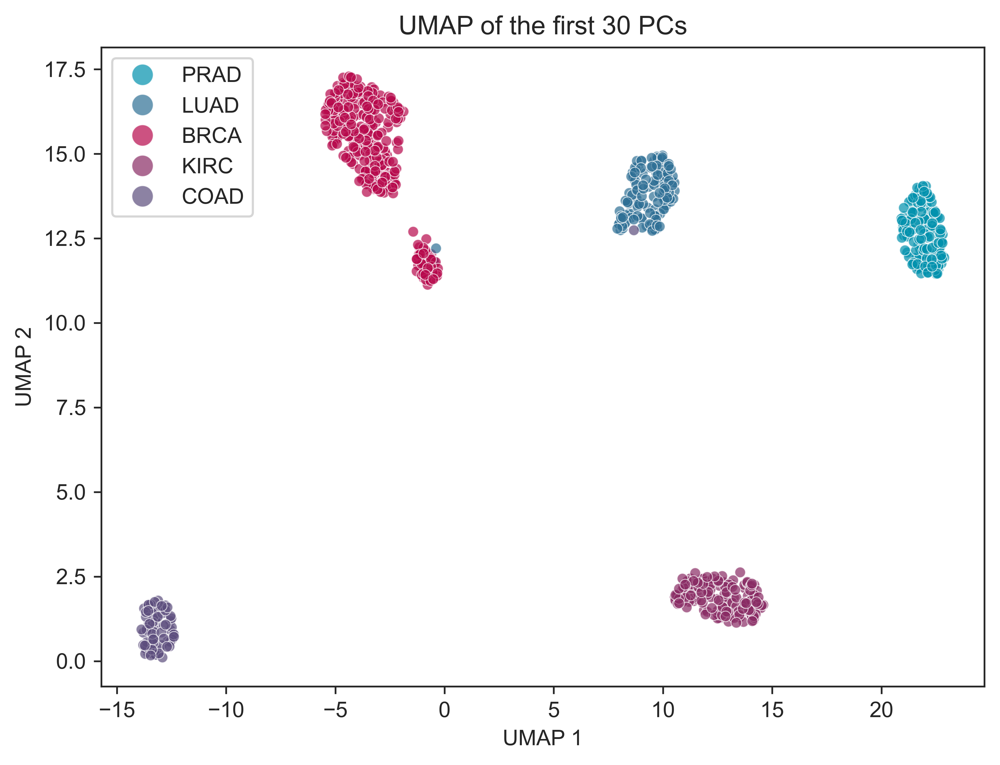

In [218]:
# UMAP on the first N_PCS principal components from Part 5
N_PCS = 30                                        # number of PCs used as input; adjust after Question 5.4
emb = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=SEED).fit_transform(scores[:, :N_PCS])   # n_neighbors = size of the local neighbourhood

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=tumour, palette=COLOURS, s=24, alpha=0.7, ax=ax)
ax.set(xlabel="UMAP 1", ylabel="UMAP 2", title=f"UMAP of the first {N_PCS} PCs"); ax.legend(markerscale=2, title=None)
plt.tight_layout(); plt.show()

**Question 6.1** Why are we able to clearly visualize the cancer types in 2 dimensions with a UMAP embedding, but need multiple PCs?

*Your answer:*


**Question 6.2** There are two samples that seem to cluster outside of their assigned label. What could be the reason for that?

*Your answer:*

**Question 6.3** Do we observe any subclusters in the UMAP embedding? Are they visible in the PCA plots? Can you notice any other issues in the plot?

*Your answer:*

**Question 6.4** Rerun UMAP with different `n_neighbors`, `N_PCS` and `random_state`. What changes, and what stays the same? (For fun)